# 01 · Datos y descriptores de los catálogos de validación

**Pregunta.** ¿Qué eventos hay en cada catálogo de validación (VOISS-Net, VCSEIS, Isla Decepción, Volcán Nevado del Ruiz), por sistema y por clase, y cómo se distribuyen los descriptores que más transfieren (FI, DET, SR) dentro de cada sistema?

Todo se muestra **por sistema**: ninguna distribución mezcla volcanes. Se usan solo eventos válidos (`motivo == ""`) y no duplicados. Decepción se separa en sus dos campañas (1995 y 2009).

Lee únicamente `../datos/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
pd.set_option("display.width", 160, "display.max_columns", 30)
DATOS, RES = Path("../datos"), Path("../resultados")

F16 = ["DET", "L", "Lmax", "DIV", "Lentr", "LAM", "TT", "Vmax", "Ventr", "W",
       "Wmax", "Wdiv", "Wentr", "fpeak", "SR", "FI"]

def cargar(ventana):
    """Eventos validos (motivo vacio, sin duplicados); Decepcion separada por campana."""
    d = pd.read_parquet(DATOS / f"features16_{ventana}.parquet")
    d = d[(d.motivo == "") & ~d.duplicado.fillna(False).astype(bool)].copy()
    dec = d.sistema == "Decepcion"
    d.loc[dec, "sistema"] = "Decepcion" + d.loc[dec, "item_id"].str.extract(r"dec\.(\d\d)")[0]
    return d

fija, coda = cargar("fija"), cargar("coda")
len(fija), len(coda)

(9325, 9132)

## Inventario por catálogo, sistema y clase (ventana fija)

In [2]:
inv = pd.crosstab([fija.dataset, fija.sistema], fija.clase, margins=True, margins_name="total")
inv

clase                          AV   EX   HB    LP   OT   RE  TR    VT  total
dataset   sistema                                                           
decepcion Decepcion09           0    0    0   175    0    0   0    24    199
          Decepcion95           0    0    0    48    0    0   0    29     77
sgc       Ruiz-Bis              0    0   70   173    0    0   0     5    248
          Ruiz-Olleta           0    0  389   176    0    0   0   216    781
vcseis    Alaska                1    0    0   459  357  163   2   416   1398
          Cascade               0    0    0   170    0    0   0   186    356
          Hawái                 0    0    0   398    0    0   0   352    750
          Norte de California   0    0    0   327    0    0   0   361    688
voissnet  Kilauea               0    0    0     0    0    0   0   878    878
          Pavlof                0  145    0    61    0    0   0     0    206
          Redoubt               0    0    0     0    0    0   0   961    961
          Semisopochnoi         0  299    0   715    0    0   0     0   1014
          Tanaga                0    0    0     0    0    0   0   936    936
          Veniaminof            0    0    0   833    0    0   0     0    833
total                           1  444  459  3535  357  163   2  4364   9325

Señales continuas (tremor, ruido), usadas solo como referencia de clase fuera de LP/VT:

In [3]:
cont = pd.read_parquet(DATOS / "features16_continuas.parquet")
cont = cont[cont.motivo == ""]
pd.crosstab([cont.dataset, cont.sistema], cont.clase)

clase                    NTR  RUIDO    TR
dataset   sistema                        
decepcion Decepcion09    435      0     0
          Decepcion95     87      0     0
sgc       Ruiz-Bis         0      0   250
          Ruiz-Olleta      0      0   250
voissnet  Pavlof           0    500  1436
          Popocatepetl     0      0   500
          Semisopochnoi    0    500   717
          Veniaminof       0      0   422

## Distribución de FI, DET y SR por sistema y clase

Cada caja es un sistema y una clase; las clases con menos de 20 eventos en un sistema no se dibujan.

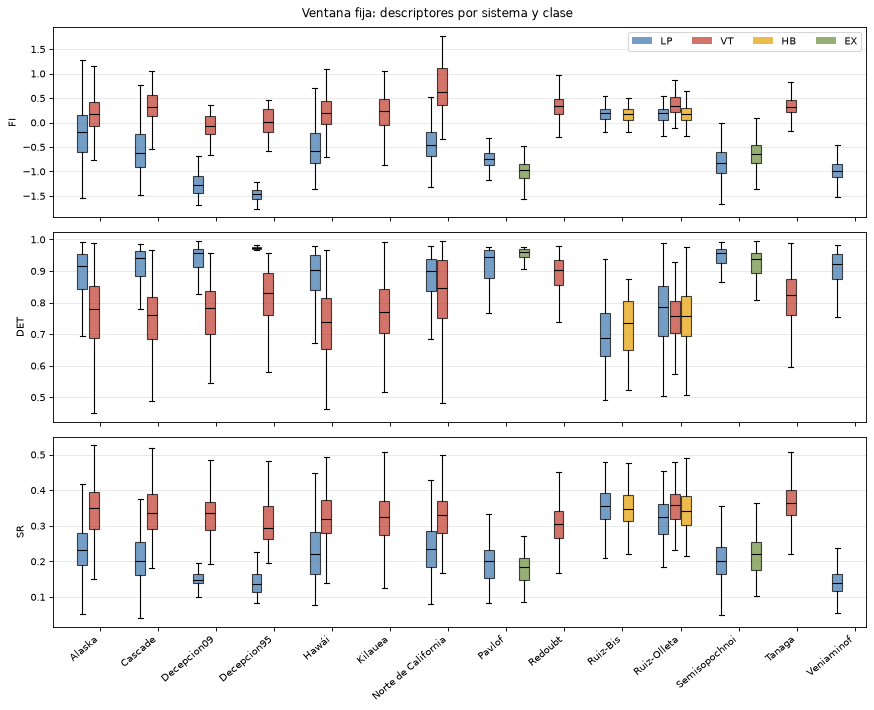

In [4]:
CLASES = ["LP", "VT", "HB", "EX"]
COLOR = {"LP": "#3b75af", "VT": "#c0392b", "HB": "#e69f00", "EX": "#6a8e3b"}
sistemas = sorted(fija.sistema.unique())
fig, ejes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, desc in zip(ejes, ["FI", "DET", "SR"]):
    for i, s in enumerate(sistemas):
        for j, c in enumerate(CLASES):
            v = fija.loc[(fija.sistema == s) & (fija.clase == c), desc].dropna()
            if len(v) < 20:
                continue
            b = ax.boxplot(v, positions=[i + (j - 1.5) * 0.2], widths=0.17, showfliers=False,
                           patch_artist=True)
            b["boxes"][0].set(facecolor=COLOR[c], alpha=.7)
            b["medians"][0].set(color="k")
    ax.set_ylabel(desc)
    ax.grid(axis="y", alpha=.3)
ejes[-1].set_xticks(range(len(sistemas)))
ejes[-1].set_xticklabels(sistemas, rotation=40, ha="right")
ejes[0].legend([plt.Rectangle((0, 0), 1, 1, fc=COLOR[c], alpha=.7) for c in CLASES], CLASES,
               ncol=4, loc="upper right")
fig.suptitle("Ventana fija: descriptores por sistema y clase")
fig.tight_layout()

Medianas por sistema y clase (LP y VT), para leer los números de la figura:

In [5]:
(fija[fija.clase.isin(["LP", "VT"])]
 .groupby(["sistema", "clase"])[["FI", "DET", "SR"]].median().round(3)
 .unstack("clase"))

FI           DET            SR       
clase                   LP     VT     LP     VT     LP     VT
sistema                                                      
Alaska              -0.194  0.182  0.917  0.781  0.231  0.350
Cascade             -0.625  0.319  0.941  0.760  0.202  0.336
Decepcion09         -1.284 -0.071  0.957  0.784  0.149  0.336
Decepcion95         -1.464  0.017  0.972  0.829  0.137  0.293
Hawái               -0.580  0.199  0.903  0.737  0.221  0.318
Kilauea                NaN  0.229    NaN  0.769    NaN  0.325
Norte de California -0.451  0.625  0.899  0.845  0.234  0.331
Pavlof              -0.745    NaN  0.945    NaN  0.202    NaN
Redoubt                NaN  0.334    NaN  0.902    NaN  0.305
Ruiz-Bis             0.192  0.302  0.687  0.722  0.356  0.354
Ruiz-Olleta          0.186  0.335  0.786  0.759  0.325  0.357
Semisopochnoi       -0.819    NaN  0.958    NaN  0.200    NaN
Tanaga                 NaN  0.322    NaN  0.823    NaN  0.365
Veniaminof          -0.982    NaN  0.923    NaN  0.139    NaN

## Relación entre ventanas (fija frente a hasta la coda)

Para los mismos eventos, correlación de Spearman entre el valor del descriptor en la ventana fija y en la ventana hasta el fin de la coda, por sistema.

In [6]:
par = fija.merge(coda, on="item_id", suffixes=("_fija", "_coda"))
par = par[par.sistema_fija == par.sistema_coda]
rho = (par.groupby("sistema_fija")
       .apply(lambda g: pd.Series({d: g[f"{d}_fija"].corr(g[f"{d}_coda"], method="spearman")
                                   for d in ["FI", "DET", "SR"]} | {"n": len(g)}))
       .rename_axis("sistema"))
rho.round(3)

,FI,DET,SR,n
sistema,,,,
Alaska,0.954,0.628,0.855,1380.0
Cascade,0.983,0.672,0.892,347.0
Decepcion09,0.960,0.943,0.935,194.0
Decepcion95,0.972,0.789,0.977,57.0
Hawái,0.983,0.720,0.853,749.0
Kilauea,0.974,0.454,0.724,878.0
Norte de California,0.996,0.615,0.918,688.0
Pavlof,0.693,0.398,0.306,206.0
Redoubt,0.983,0.691,0.876,961.0


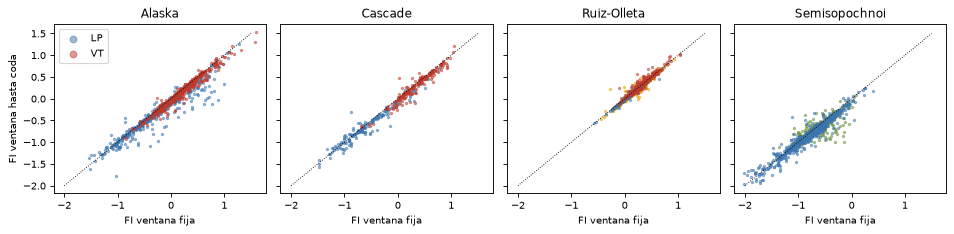

In [7]:
muestra = ["Alaska", "Cascade", "Ruiz-Olleta", "Semisopochnoi"]
fig, ejes = plt.subplots(1, len(muestra), figsize=(12, 3), sharex=True, sharey=True)
for ax, s in zip(ejes, muestra):
    g = par[(par.sistema_fija == s) & par.clase_fija.isin(["LP", "VT", "HB", "EX"])]
    for c, h in g.groupby("clase_fija"):
        ax.scatter(h.FI_fija, h.FI_coda, s=4, alpha=.5, color=COLOR[c], label=c)
    ax.plot([-2, 1.5], [-2, 1.5], "k:", lw=.8)
    ax.set_title(s); ax.set_xlabel("FI ventana fija")
ejes[0].set_ylabel("FI ventana hasta coda"); ejes[0].legend(markerscale=3)
fig.tight_layout()